# 01 — EDA, group-aware validation split, TF-IDF baseline
**Kaggle settings:** Accelerator = None (CPU), Internet = Off is fine.
**Inputs:** the competition data.
**Outputs (in /kaggle/working):** `folds.csv` (fixed split used by all notebooks),
`val_baseline.csv`, `test_baseline.csv` (class scores), `submission_baseline.csv`, `figs/*.png`.

In [1]:
import os, glob, time, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

INPUT_ROOT = os.environ.get("INPUT_ROOT", "/kaggle/input")
OUT = os.environ.get("OUT_DIR", "/kaggle/working")
os.makedirs(f"{OUT}/figs", exist_ok=True)

def find(name):
    hits = sorted(glob.glob(f"{INPUT_ROOT}/**/{name}", recursive=True))
    assert hits, f"{name} not found under {INPUT_ROOT}: add it via '+ Add Input'"
    return hits[0]

SEED = 42
LABELS = ["human", "ai", "fusion"]
L2I = {l: i for i, l in enumerate(LABELS)}
N_SAMPLE = int(os.environ.get("N_SAMPLE", 60000))  # fixed working subsample of train.csv
N_FOLDS = 5          # fold 0 = validation, folds 1-4 = training part
SIM_THR = 0.5        # cosine threshold for "same source text" (check the diagnostics below)
MAX_CHARS = 15000    # truncation for TF-IDF only (speed)

In [2]:
train = pd.read_csv(find("train.csv"))
test = pd.read_csv(find("test.csv"))
sample_sub = pd.read_csv(find("sample_submission.csv"))
print(train.shape, test.shape, sample_sub.shape)
for d in (train, test):
    d["n_words"] = d["text"].str.count(r"\S+")

(272352, 5) (25000, 4) (25000, 2)


## EDA: class balance by language and domain

label
ai        0.448
fusion    0.307
human     0.245
label                             ai  fusion  human     All
lang  domain                                               
de-DE bundestag                19977   17887  14479   52343
      gutenberg                  360      37     31     428
en-EN arxiv_papers             12050    1833    407   14290
      blog_authorship_corpus   15684   12397  12466   40547
      cnn_news                 19488   11402  13395   44285
      euro_court_cases         11141   10160   6277   27578
      gutenberg                 6359     341    216    6916
      house_of_commons         15298    9608   6953   31859
      student_essays           21583   20017  12506   54106
All                           121940   83682  66730  272352


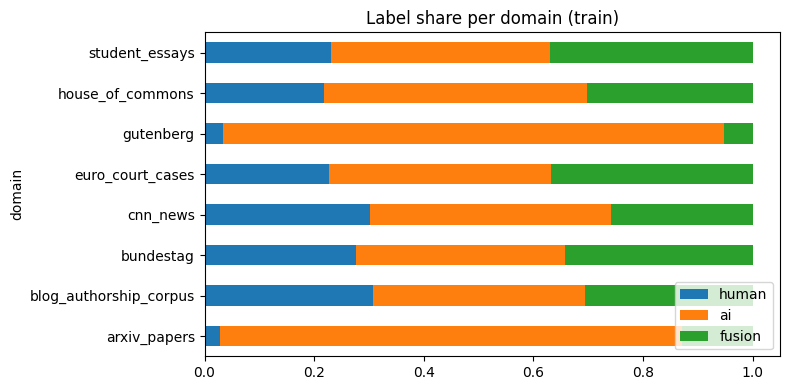

                        train   test
domain                              
student_essays          0.199  0.159
bundestag               0.192  0.143
cnn_news                0.163  0.197
blog_authorship_corpus  0.149  0.178
house_of_commons        0.117  0.118
euro_court_cases        0.101  0.064
arxiv_papers            0.052  0.067
gutenberg               0.027  0.074
       train   test
lang               
en-EN  0.806  0.853
de-DE  0.194  0.147


In [3]:
print(train["label"].value_counts(normalize=True).round(3).to_string())
display_tbl = pd.crosstab([train["lang"], train["domain"]], train["label"], margins=True)
print(display_tbl.to_string())

# share of each label inside each domain
share = pd.crosstab(train["domain"], train["label"], normalize="index")[LABELS]
ax = share.plot.barh(stacked=True, figsize=(8, 4), title="Label share per domain (train)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(f"{OUT}/figs/label_by_domain.png", dpi=120); plt.show()

# train vs test domain/lang distribution (distribution shift check)
dist = pd.concat({"train": train["domain"].value_counts(normalize=True),
                  "test": test["domain"].value_counts(normalize=True)}, axis=1).round(3)
print(dist.to_string())
print(pd.concat({"train": train["lang"].value_counts(normalize=True),
                 "test": test["lang"].value_counts(normalize=True)}, axis=1).round(3).to_string())

## EDA: text lengths

         mean    25%    50%    75%     max
label                                     
ai      493.0  287.0  465.0  657.0  2996.0
fusion  585.0  263.0  445.0  695.0  3000.0
human   578.0  262.0  481.0  740.0  2998.0


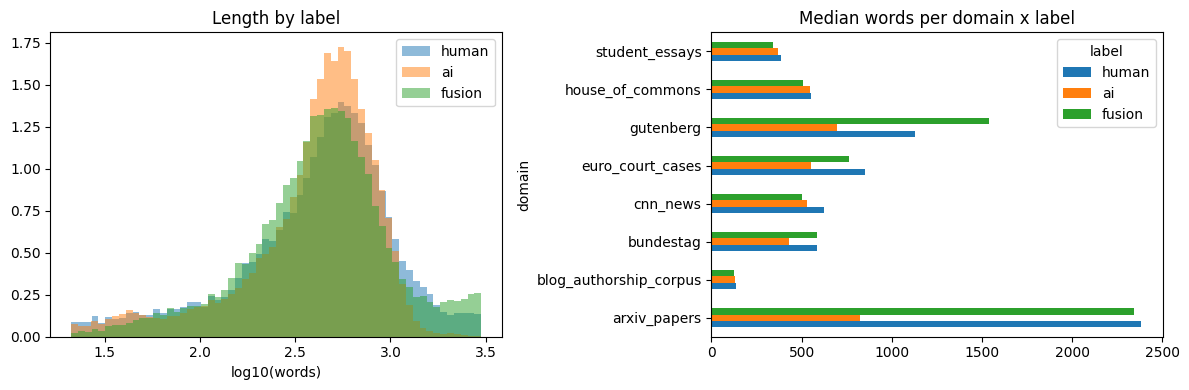

share > 390 words: 0.603


In [4]:
print(train.groupby("label")["n_words"].describe()[["mean", "25%", "50%", "75%", "max"]].round(0).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for l in LABELS:
    ax[0].hist(np.log10(train.loc[train.label == l, "n_words"] + 1), bins=60, alpha=0.5, label=l, density=True)
ax[0].set_xlabel("log10(words)"); ax[0].legend(); ax[0].set_title("Length by label")
med = train.groupby(["domain", "label"])["n_words"].median().unstack()[LABELS]
med.plot.barh(ax=ax[1], title="Median words per domain x label")
plt.tight_layout(); plt.savefig(f"{OUT}/figs/lengths.png", dpi=120); plt.show()
# rough share of texts longer than a 512-token window (~1.3 tokens/word for XLM-R/mDeBERTa)
print("share > 390 words:", (train["n_words"] > 390).mean().round(3))

## EDA: examples of each class (truncated)

In [5]:
for lang in ["en-EN", "de-DE"]:
    for l in LABELS:
        r = train[(train.lang == lang) & (train.label == l)].sample(1, random_state=SEED).iloc[0]
        print(f"[{lang} | {l} | {r.domain}] {r.text[:300]!r}\n")

[en-EN | human | euro_court_cases] '8. The applicant was born in 1946 and lives in Szamotuły, Poland. 9. On 30 July 1987 the applicant lodged a claim for payment against the Wielkopolska Gardening Co‑operative (Wielkopolska Spółdzielnia Ogrodnicza) with the Poznań District Court (Sąd Rejonowy). On 3 November 1987 the Polcomex Ltd join'

[en-EN | ai | student_essays] 'The Benefits of Limiting Car Usage: A Path Towards Sustainable Urban Living In recent years, urban planners and environmentalists have increasingly advocated for reduced car usage as a means to address pressing environmental and social issues. Limiting car usage presents a multitude of benefits, inc'

[en-EN | fusion | house_of_commons] 'I am grateful for this opportunity to raise an issue that has annoyed and upset some of my constituents for more than two years. For reasons that will become clear during my speech, it has also caused considerable irritation to their Member of Parliament. The constituents live on a new, pr

## EDA: simple stylometry per class (what makes fusion different?)

In [6]:
def stylo(texts):
    s = pd.Series(texts)
    words = s.str.split()
    sents = s.str.split(r"(?<=[.!?])\s+")
    sent_len = sents.apply(lambda x: [len(t.split()) for t in x if t.strip()])
    return pd.DataFrame({
        "avg_word_len": words.apply(lambda w: np.mean([len(t) for t in w]) if w else 0),
        "avg_sent_len": sent_len.apply(lambda x: np.mean(x) if x else 0),
        "std_sent_len": sent_len.apply(lambda x: np.std(x) if x else 0),
        "ttr_300": words.apply(lambda w: len(set(w[:300])) / max(1, len(w[:300]))),
        "comma_rate": s.str.count(",") / s.str.len().clip(lower=1) * 1000,
        "excl_q_rate": s.str.count(r"[!?]") / s.str.len().clip(lower=1) * 1000,
        "dash_rate": s.str.count("[—–]") / s.str.len().clip(lower=1) * 1000,
    })

eda_s = train.sample(frac=1, random_state=SEED).groupby("label").head(5000)
st = stylo(eda_s["text"].values); st["label"] = eda_s["label"].values
print(st.groupby("label").mean().loc[LABELS].round(3).to_string())

        avg_word_len  avg_sent_len  std_sent_len  ttr_300  comma_rate  excl_q_rate  dash_rate
label                                                                                        
human          4.971        18.851        11.448    0.639       8.003        1.122      0.362
ai             5.541        18.399         7.990    0.696       9.319        1.901      0.425
fusion         5.163        17.806        10.442    0.650       8.035        1.000      0.305


## Fixed working subsample + group-aware split
A human text and its AI/fusion versions must stay on the same side of the split (as in train/test).
There is no group id, so we recover groups as connected components of a near-duplicate graph
(TF-IDF word 1-2 grams, cosine >= SIM_THR, within the same lang+domain). This vectorizer is only
used to define the split on train rows; it never sees test and is not a model feature.

working sample: (60001, 6)
edges >= 0.5: 11960, groups: 54810, rows in groups of size>1: 0.161


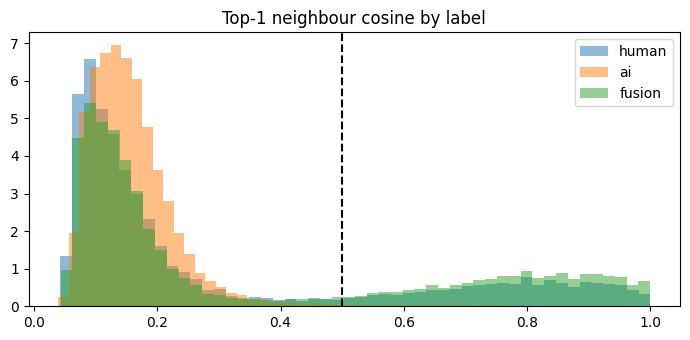

label of nearest neighbour (only pairs >= threshold), rows = own label:
col_0   human   ai  fusion
label                     
human     184   15    3382
ai         16  224       3
fusion   3288    2    2524
median top-1 similarity by label: {'ai': 0.146, 'fusion': 0.169, 'human': 0.152}


In [7]:
frac = min(1.0, N_SAMPLE / len(train))
work = (train.groupby(["label", "lang", "domain"], group_keys=False)
             .sample(frac=frac, random_state=SEED).reset_index(drop=True))
print("working sample:", work.shape)

rows, cols, sims = [], [], []
top1_sim = np.zeros(len(work)); top1_idx = np.arange(len(work))
for (lang, dom), idx in work.groupby(["lang", "domain"]).indices.items():
    if len(idx) < 3:
        continue
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_df=0.5, max_features=300000)
    X = vec.fit_transform(work["text"].values[idx].astype(str))
    k = min(6, len(idx))
    nn = NearestNeighbors(n_neighbors=k, metric="cosine", algorithm="brute", n_jobs=-1).fit(X)
    dist, nbr = nn.kneighbors(X)
    s = 1 - dist[:, 1:]; nb = nbr[:, 1:]
    top1_sim[idx] = s[:, 0]; top1_idx[idx] = idx[nb[:, 0]]
    m = s >= SIM_THR
    rows.append(np.repeat(idx, k - 1)[m.ravel()]); cols.append(idx[nb][m]); sims.append(s[m])
rows, cols = np.concatenate(rows), np.concatenate(cols)
G = sparse.coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(work), len(work)))
n_groups, group = connected_components(G, directed=False)
work["group"] = group
print(f"edges >= {SIM_THR}: {len(rows)}, groups: {n_groups}, "
      f"rows in groups of size>1: {(work.groupby('group')['id'].transform('size') > 1).mean():.3f}")

# diagnostics: how close is each text to its nearest neighbour, and what label is that neighbour?
fig, ax = plt.subplots(figsize=(7, 3.5))
for l in LABELS:
    ax.hist(top1_sim[work.label == l], bins=50, alpha=0.5, label=l, density=True)
ax.axvline(SIM_THR, color="k", ls="--"); ax.set_title("Top-1 neighbour cosine by label"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/figs/nn_similarity.png", dpi=120); plt.show()
close = top1_sim >= SIM_THR
print("label of nearest neighbour (only pairs >= threshold), rows = own label:")
print(pd.crosstab(work.label[close], work.label.values[top1_idx[close]]).reindex(index=LABELS, columns=LABELS, fill_value=0).to_string())
print("median top-1 similarity by label:", pd.Series(top1_sim).groupby(work.label).median().round(3).to_dict())

In [8]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
work["fold"] = -1
for f, (_, va) in enumerate(sgkf.split(work, work["label"], work["group"])):
    work.loc[va, "fold"] = f
tr_m, va_m = work.fold != 0, work.fold == 0
print("train part:", tr_m.sum(), " val:", va_m.sum())
print(pd.crosstab(work.fold == 0, work.label, normalize="index").round(3).to_string())
assert not set(work.group[tr_m]) & set(work.group[va_m])
work[["id", "fold", "group", "label", "lang", "domain"]].to_csv(f"{OUT}/folds.csv", index=False)

train part: 47853  val: 12148
label     ai  fusion  human
fold                       
False  0.447   0.308  0.245
True   0.449   0.304  0.247


## Baseline: TF-IDF (word + char) + linear models
Vectorizers are fit on the training part only; validation and test are only transformed.

In [9]:
y = work["label"].map(L2I).values
y_tr, y_va = y[tr_m.values], y[va_m.values]
txt = work["text"].str.slice(0, MAX_CHARS).values
t0 = time.time()
vec_w = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300000, sublinear_tf=True)
vec_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, max_features=300000, sublinear_tf=True)
Xw_tr = vec_w.fit_transform(txt[tr_m.values]); Xw_va = vec_w.transform(txt[va_m.values])
Xc_tr = vec_c.fit_transform(txt[tr_m.values]); Xc_va = vec_c.transform(txt[va_m.values])
X_tr = sparse.hstack([Xw_tr, Xc_tr]).tocsr(); X_va = sparse.hstack([Xw_va, Xc_va]).tocsr()
print(f"vectorized in {time.time()-t0:.0f}s, X_tr={X_tr.shape}")

vectorized in 410s, X_tr=(47853, 600000)


In [10]:
results = []
def run(name, model, Xtr, Xva, feats):
    t = time.time(); model.fit(Xtr, y_tr); p = model.predict(Xva)
    f = f1_score(y_va, p, average="macro")
    results.append({"model": name, "features": feats, "val_macro_f1": round(f, 4), "sec": round(time.time() - t)})
    print(results[-1]); return model

for C in [0.1, 0.3, 1.0]:
    run(f"LinearSVC C={C}", LinearSVC(C=C), X_tr, X_va, "word+char")
for C in [4.0, 16.0]:
    run(f"LogReg C={C}", LogisticRegression(C=C, max_iter=300), X_tr, X_va, "word+char")
run("ComplementNB a=0.1", ComplementNB(alpha=0.1), X_tr, X_va, "word+char")
res = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
best_svc_C = float(res[res.model.str.startswith("LinearSVC")].iloc[0].model.split("=")[1])
run(f"LinearSVC C={best_svc_C}", LinearSVC(C=best_svc_C), Xw_tr, Xw_va, "word only")
run(f"LinearSVC C={best_svc_C}", LinearSVC(C=best_svc_C), Xc_tr, Xc_va, "char only")
res = pd.DataFrame(results).sort_values("val_macro_f1", ascending=False)
print(res.to_string(index=False)); res.to_csv(f"{OUT}/baseline_results.csv", index=False)

{'model': 'LinearSVC C=0.1', 'features': 'word+char', 'val_macro_f1': 0.8581, 'sec': 33}
{'model': 'LinearSVC C=0.3', 'features': 'word+char', 'val_macro_f1': 0.8679, 'sec': 44}
{'model': 'LinearSVC C=1.0', 'features': 'word+char', 'val_macro_f1': 0.8666, 'sec': 77}
{'model': 'LogReg C=4.0', 'features': 'word+char', 'val_macro_f1': 0.8778, 'sec': 229}
{'model': 'LogReg C=16.0', 'features': 'word+char', 'val_macro_f1': 0.8794, 'sec': 261}
{'model': 'ComplementNB a=0.1', 'features': 'word+char', 'val_macro_f1': 0.6593, 'sec': 2}
{'model': 'LinearSVC C=0.3', 'features': 'word only', 'val_macro_f1': 0.8408, 'sec': 6}
{'model': 'LinearSVC C=0.3', 'features': 'char only', 'val_macro_f1': 0.8551, 'sec': 29}
             model  features  val_macro_f1  sec
     LogReg C=16.0 word+char        0.8794  261
      LogReg C=4.0 word+char        0.8778  229
   LinearSVC C=0.3 word+char        0.8679   44
   LinearSVC C=1.0 word+char        0.8666   77
   LinearSVC C=0.1 word+char        0.8581   33
  

## Best baseline: per-class metrics, confusion matrix, per-language / per-domain F1

LogReg C=16.0 macro-F1: 0.8794
              precision    recall  f1-score   support

       human     0.7853    0.8611    0.8215      2995
          ai     0.9823    0.9892    0.9858      5456
      fusion     0.8712    0.7942    0.8309      3697

    accuracy                         0.8983     12148
   macro avg     0.8796    0.8815    0.8794     12148
weighted avg     0.9000    0.8983    0.8981     12148



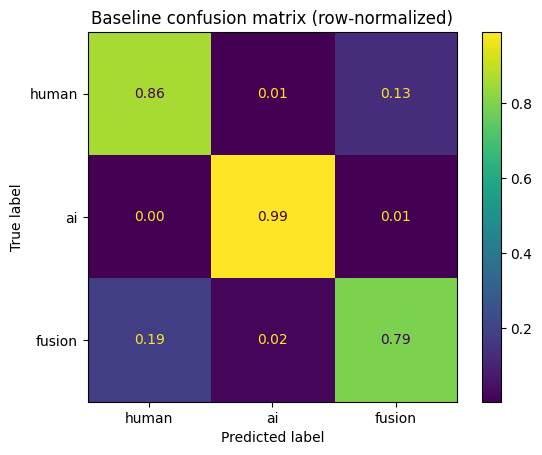

lang
de-DE    0.9090
en-EN    0.8713
domain
arxiv_papers              0.8791
blog_authorship_corpus    0.7638
bundestag                 0.9089
cnn_news                  0.8975
euro_court_cases          0.9073
gutenberg                 0.7992
house_of_commons          0.8832
student_essays            0.8938


/tmp/ipykernel_17/182253020.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(va.groupby("lang").apply(lambda d: f1_score(d.y, d.pred, average="macro")).round(4).to_string())
/tmp/ipykernel_17/182253020.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(va.groupby("domain").apply(lambda d: f1_score(d.y, d.pred, average="macro")).round(4).to_string())


In [11]:
best = res[res.features == "word+char"].iloc[0]
C = float(best.model.split("=")[1])
model = LinearSVC(C=C) if best.model.startswith("LinearSVC") else (
        LogisticRegression(C=C, max_iter=300) if best.model.startswith("LogReg") else ComplementNB(alpha=C))
model.fit(X_tr, y_tr)

def scores(m, X):
    if hasattr(m, "decision_function"):
        return m.decision_function(X)
    return np.log(m.predict_proba(X) + 1e-9)

s_va = scores(model, X_va); p_va = s_va.argmax(1)
print(best.model, "macro-F1:", round(f1_score(y_va, p_va, average="macro"), 4))
print(classification_report(y_va, p_va, target_names=LABELS, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_va, p_va, normalize="true"), display_labels=LABELS).plot(values_format=".2f")
plt.title("Baseline confusion matrix (row-normalized)"); plt.savefig(f"{OUT}/figs/cm_baseline.png", dpi=120); plt.show()
va = work[va_m].assign(pred=p_va, y=y_va)
print(va.groupby("lang").apply(lambda d: f1_score(d.y, d.pred, average="macro")).round(4).to_string())
print(va.groupby("domain").apply(lambda d: f1_score(d.y, d.pred, average="macro")).round(4).to_string())

## What does the linear model rely on? (top word n-grams per class, LogReg on word features)

In [12]:
lr_w = LogisticRegression(C=4.0, max_iter=300).fit(Xw_tr, y_tr)
vocab = np.array(vec_w.get_feature_names_out())
for i, l in enumerate(LABELS):
    print(f"{l:7s}:", ", ".join(vocab[np.argsort(lr_w.coef_[i])[::-1][:20]]))

human  : dank, urllink, vielen dank, vielen, danke, in conclusion, herzlichen dank, herzlichen, student_name, will, do, have, cnn, of the, auch, very, conclusion, am, in the, should
ai     : let, just, this, like, maybe, significant, seriously, gotta, super, legal, it like, potential, within, these, text, honestly, feels, regarding, about, unserer
fusion : and, furthermore, me know, missing, missing part, let me, we must, the, moreover, missing section, know if, additionally, sondern auch, es ist, wir müssen, reconstructed, to, müssen uns, of, must


## Predict test, save scores for the ensemble, write a submission

In [13]:
txt_te = test["text"].str.slice(0, MAX_CHARS).values
X_te = sparse.hstack([vec_w.transform(txt_te), vec_c.transform(txt_te)]).tocsr()
s_te = scores(model, X_te)
cols = [f"s_{l}" for l in LABELS]
pd.DataFrame(s_va, columns=cols).assign(id=work.id[va_m].values).to_csv(f"{OUT}/val_baseline.csv", index=False)
pd.DataFrame(s_te, columns=cols).assign(id=test.id.values).to_csv(f"{OUT}/test_baseline.csv", index=False)

def write_submission(ids, pred_idx, path):
    sub = pd.DataFrame({"id": ids, "label": np.array(LABELS)[pred_idx]})
    sub = sample_sub[["id"]].merge(sub, on="id", how="left")
    assert len(sub) == len(sample_sub) and sub.id.is_unique and sub.label.isin(LABELS).all()
    sub.to_csv(path, index=False); print(path, sub.label.value_counts(normalize=True).round(3).to_dict())

write_submission(test.id.values, s_te.argmax(1), f"{OUT}/submission_baseline.csv")

/kaggle/working/submission_baseline.csv {'ai': 0.519, 'human': 0.262, 'fusion': 0.219}
